正在计算 g=1.5, odd猫态的情况 (5x5共25张图)，请稍候...
计算完成！全局数值范围设定为: [-0.318, 0.318]
正在显示图像...


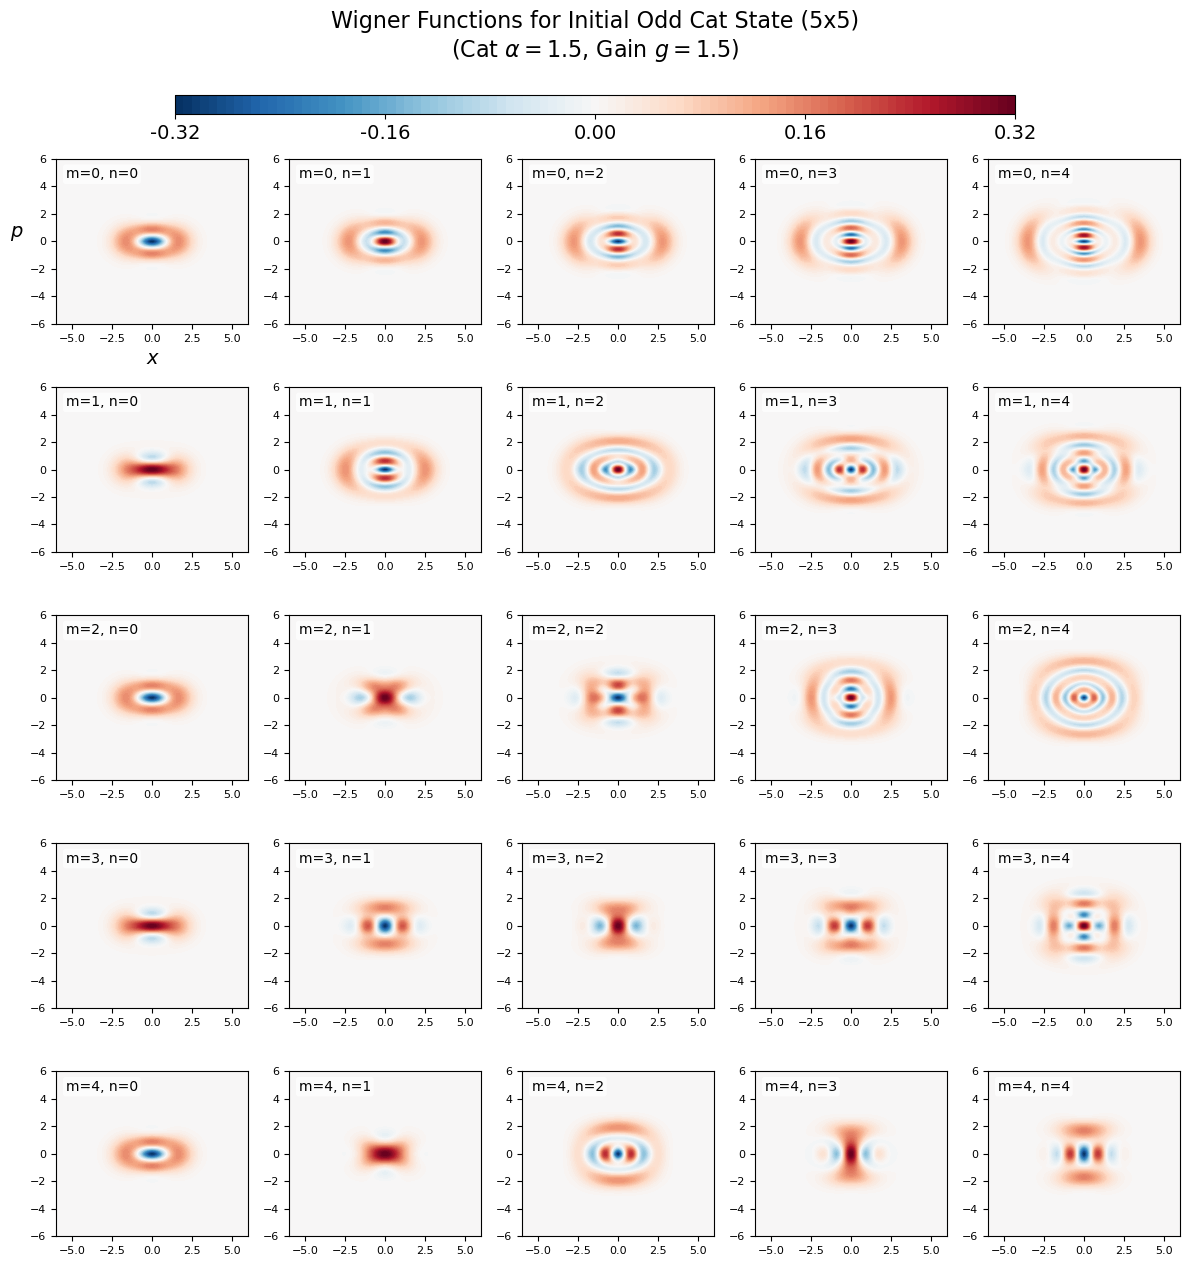

In [1]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt

def plot_wigner_cat_amplifier_5x5_perfect(g_val, cat_alpha=1.0, cat_type="odd", N_dim=100):
    if g_val < 1.0:
        raise ValueError("物理错误：放大增益 g 的值必须大于或等于 1.0")

    print(f"正在计算 g={g_val}, {cat_type}猫态的情况 (5x5共25张图)，请稍候...")

    # ==========================================
    # 1. 物理参数与算符初始化
    # ==========================================
    m_list = [0, 1, 2, 3, 4]
    n_list = [0, 1, 2, 3, 4]
    
    g = g_val
    G = np.sqrt(1 - 1 / (g**2)) 

    a = qt.destroy(N_dim)
    adag = a.dag()

    g_op_diag = [g**(-j) for j in range(N_dim)]
    g_op = qt.Qobj(np.diag(g_op_diag), dims=[[N_dim], [N_dim]])

    alpha_plus = qt.coherent(N_dim, cat_alpha)
    alpha_minus = qt.coherent(N_dim, -cat_alpha)

    if cat_type == "even":
        phi_state = (alpha_plus + alpha_minus).unit()
    elif cat_type == "odd":
        phi_state = (alpha_plus - alpha_minus).unit()

    xvec = np.linspace(-6, 6, 200)

    # ==========================================
    # 2. 一次性计算并存储所有 Wigner 矩阵
    # ==========================================
    wigner_matrices = np.zeros((len(m_list), len(n_list), len(xvec), len(xvec)))

    for i, m in enumerate(m_list):
        for j, n in enumerate(n_list):
            psi_out = qt.basis(N_dim, 0) * 0.0
            for k in range(m + 1):
                if n - m + k < 0:
                    continue
                num1 = (-1)**(n - m + k)
                den1 = g**(m - k + 1)
                num2 = (G**(n - m + 2 * k)) * math.sqrt(math.factorial(n) * math.factorial(m))
                den2 = math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
                coef = (num1 / den1) * (num2 / den2)
                term_state = coef * (adag**(n - m + k)) * g_op * (a**k) * phi_state
                psi_out += term_state
            
            psi = psi_out.unit()
            wigner_matrices[i, j] = qt.wigner(psi, xvec, xvec)

    max_w = np.max(np.abs(wigner_matrices))
    print(f"计算完成！全局数值范围设定为: [{-max_w:.3f}, {max_w:.3f}]")

    # ==========================================
    # 3. 绘图与排版
    # ==========================================
    fig, axes = plt.subplots(5, 5, figsize=(12, 13)) 
    
    levels = np.linspace(-max_w, max_w, 100)

    for i, m in enumerate(m_list):       
        for j, n in enumerate(n_list):   
            ax = axes[i, j] 
            W = wigner_matrices[i, j]

            # 修复 1：去掉了 extend='both'，现在两端是平齐的矩形，没有箭头了
            cont = ax.contourf(xvec, xvec, W, levels=levels, cmap='RdBu_r')
            
            ax.set_facecolor('whitesmoke')
            ax.set_xlabel('')
            ax.set_ylabel('')
            
            if i == 0 and j == 0:
                ax.set_xlabel('x', fontsize=14, fontstyle='italic')
                ax.set_ylabel('p', fontsize=14, fontstyle='italic', rotation=0, labelpad=10)
            
            ax.text(0.05, 0.95, f"m={m}, n={n}", transform=ax.transAxes, 
                    fontsize=10, verticalalignment='top', horizontalalignment='left',
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))
            
            ax.tick_params(axis='both', which='major', labelsize=8)

    # 先执行 tight_layout 安排好 5x5 子图的位置 (留出顶部空间 0.88 以上的区域)
    plt.tight_layout(rect=[0, 0.01, 1, 0.88])

    # ==========================================
    # 4. ★ 修复 2 & 3：绝对定位生成色条 ★
    # ==========================================
    cbar_ticks = [-max_w, -max_w/2, 0, max_w/2, max_w]
    
    # [左边距, 下边距, 宽度, 高度(厚度)]，你可以随意修改这四个数来调整色条外观
    # 现在的设置会让色条在图的正上方，细长，且不和图片粘连
    cbar_ax = fig.add_axes([0.15, 0.90, 0.7, 0.015]) 
    
    cbar = fig.colorbar(mappable=cont, cax=cbar_ax, orientation='horizontal', ticks=cbar_ticks)
    cbar.ax.set_xticklabels([f"{t:.2f}" for t in cbar_ticks], fontsize=14)

    # ==========================================
    # 5. 整体排版优化与显示
    # ==========================================
    fig.suptitle(f"Wigner Functions for Initial {cat_type.capitalize()} Cat State (5x5)\n"
                 f"(Cat $\\alpha={cat_alpha}$, Gain $g={g_val}$)", 
                 fontsize=16, y=0.98)

    print("正在显示图像...")
    plt.show()

# 运行代码
plot_wigner_cat_amplifier_5x5_perfect(g_val=1.5, cat_type="odd")

正在计算 g=1.5, even猫态的情况 (5x5共25张图)，请稍候...
计算完成！全局数值范围设定为: [-0.318, 0.318]
图像已保存为高清矢量图：wigner_cat_even_5x5_g1.5.pdf
正在显示图像...


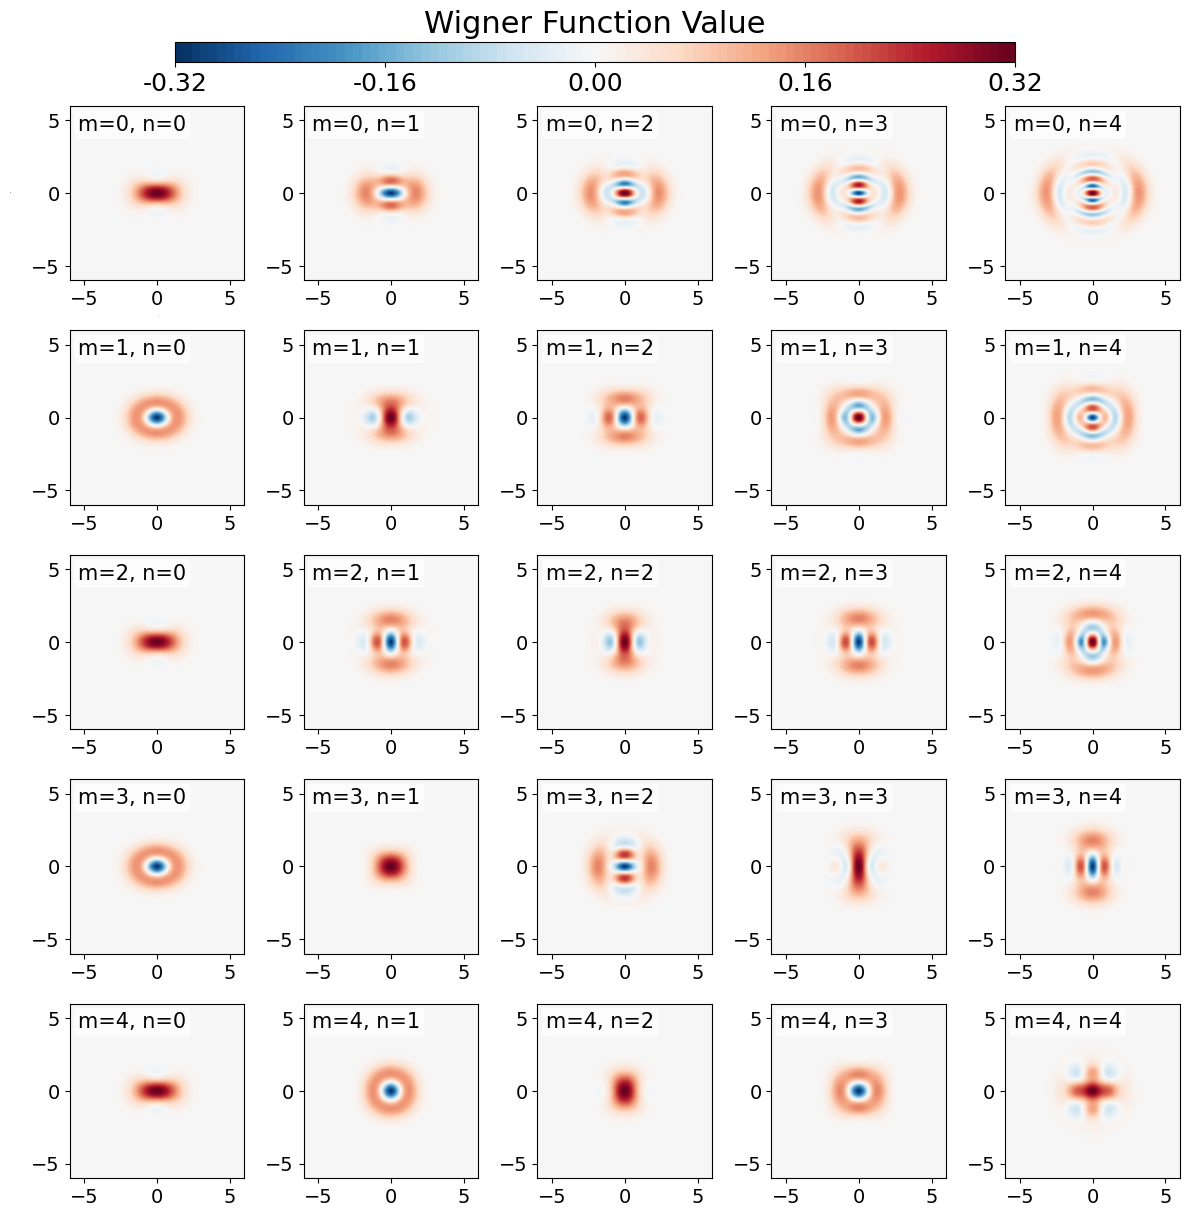

In [1]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt

def plot_wigner_cat_amplifier_5x5_perfect(g_val, cat_alpha=1.0, cat_type="even", N_dim=100):
    if g_val < 1.0:
        raise ValueError("物理错误：放大增益 g 的值必须大于或等于 1.0")

    # ==========================================
    # --- 字体与排版参数设置区 ---
    # ==========================================
    FIG_SIZE = (12, 13)        # 画布整体尺寸 (宽, 高)
    TITLE_SIZE = 18            # 总标题字体大小
    LABEL_SIZE = 1            # 坐标轴标签 (x, p) 字体大小
    TICK_SIZE = 14             # 子图坐标轴刻度数字大小
    TEXT_BOX_SIZE = 15         # 子图内 "m=, n=" 文本框字体大小
    CBAR_TICK_SIZE = 18        # 顶部色条数字刻度大小
    # ==========================================

    print(f"正在计算 g={g_val}, {cat_type}猫态的情况 (5x5共25张图)，请稍候...")

    # ==========================================
    # 1. 物理参数与算符初始化
    # ==========================================
    m_list = [0, 1, 2, 3, 4]
    n_list = [0, 1, 2, 3, 4]
    
    g = g_val
    G = np.sqrt(1 - 1 / (g**2)) 

    a = qt.destroy(N_dim)
    adag = a.dag()

    g_op_diag = [g**(-j) for j in range(N_dim)]
    g_op = qt.Qobj(np.diag(g_op_diag), dims=[[N_dim], [N_dim]])

    alpha_plus = qt.coherent(N_dim, cat_alpha)
    alpha_minus = qt.coherent(N_dim, -cat_alpha)

    if cat_type == "even":
        phi_state = (alpha_plus + alpha_minus).unit()
    elif cat_type == "odd":
        phi_state = (alpha_plus - alpha_minus).unit()

    xvec = np.linspace(-6, 6, 200)

    # ==========================================
    # 2. 一次性计算并存储所有 Wigner 矩阵
    # ==========================================
    wigner_matrices = np.zeros((len(m_list), len(n_list), len(xvec), len(xvec)))

    for i, m in enumerate(m_list):
        for j, n in enumerate(n_list):
            psi_out = qt.basis(N_dim, 0) * 0.0
            for k in range(m + 1):
                if n - m + k < 0:
                    continue
                num1 = (-1)**(n - m + k)
                den1 = g**(m - k + 1)
                num2 = (G**(n - m + 2 * k)) * math.sqrt(math.factorial(n) * math.factorial(m))
                den2 = math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
                coef = (num1 / den1) * (num2 / den2)
                term_state = coef * (adag**(n - m + k)) * g_op * (a**k) * phi_state
                psi_out += term_state
            
            psi = psi_out.unit()
            wigner_matrices[i, j] = qt.wigner(psi, xvec, xvec)

    max_w = np.max(np.abs(wigner_matrices))
    print(f"计算完成！全局数值范围设定为: [{-max_w:.3f}, {max_w:.3f}]")

    # ==========================================
    # 3. 绘图与排版
    # ==========================================
    fig, axes = plt.subplots(5, 5, figsize=FIG_SIZE) 
    
    levels = np.linspace(-max_w, max_w, 100)

    for i, m in enumerate(m_list):       
        for j, n in enumerate(n_list):   
            ax = axes[i, j] 
            W = wigner_matrices[i, j]

            cont = ax.contourf(xvec, xvec, W, levels=levels, cmap='RdBu_r')
            
            ax.set_facecolor('whitesmoke')
            ax.set_aspect('equal', adjustable='box')
            
            # ★ 限制所有子图只显示 -5, 0, 5 刻度
            ax.set_xticks([-5, 0, 5])
            ax.set_yticks([-5, 0, 5])
            
         # ★ 更改：仅在第一张图 (左上角, i=0 且 j=0) 显示字母 x 和 p
            if i == 0 and j == 0:
                ax.set_xlabel('x', fontsize=LABEL_SIZE, fontstyle='italic')
                ax.set_ylabel('p', fontsize=LABEL_SIZE, fontstyle='italic', rotation=0, labelpad=15)
            else:
                ax.set_xlabel('')
                ax.set_ylabel('')
            
            # 子图左上角参数框
            ax.text(0.05, 0.95, f"m={m}, n={n}", transform=ax.transAxes, 
                    fontsize=TEXT_BOX_SIZE, verticalalignment='top', horizontalalignment='left',
                    bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.2'))
            
            # 刻度大小
            ax.tick_params(axis='both', which='major', labelsize=TICK_SIZE)

    # 为了防止每个图都有坐标导致互相挤压，这里适当增加了 w_pad 和 h_pad 的间距
    plt.tight_layout(rect=[0, 0.01, 1, 0.88], w_pad=1.5, h_pad=1.5)

    # ==========================================
    # 4. 绝对定位生成色条
    # ==========================================
    cbar_ticks = [-max_w, -max_w/2, 0, max_w/2, max_w]
    cbar_ax = fig.add_axes([0.15, 0.90, 0.7, 0.015]) 
    
    cbar = fig.colorbar(mappable=cont, cax=cbar_ax, orientation='horizontal', ticks=cbar_ticks)
    cbar.ax.set_xticklabels([f"{t:.2f}" for t in cbar_ticks], fontsize=CBAR_TICK_SIZE)

    # ==========================================
    # 5. 整体排版优化与显示/导出
    # ==========================================

    export_filename = f"wigner_cat_{cat_type}_5x5_g{g_val}.pdf"
    plt.savefig(export_filename, format='pdf', bbox_inches='tight')
    print(f"图像已保存为高清矢量图：{export_filename}")
    fig.suptitle(f"Wigner Function Value", fontsize=22, y=0.94)
    print("正在显示图像...")
    plt.show()

# 运行代码
plot_wigner_cat_amplifier_5x5_perfect(g_val=1.5, cat_type="even")